# SPSA for Layer-Wise Training of Deep Networks

**One SPSA step**
1. Pick a random direction `delta` made of +1 and -1.
2. Measure the loss a little forward and a little backward along it.
3. Estimate the gradient: `g = (loss_plus - loss_minus) / (2*c) * delta`
4. Update: `theta = theta - a * g`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(0)

## Function Minimization

$$f(x, y) = (x-3)^2 + (y-2)^2$$

In [2]:
def f(p):
    return (p[0] - 3)**2 + (p[1] - 2)**2

def spsa_step(loss, theta, a, c):
    delta = np.random.choice([-1, 1], size=theta.shape)      # random +1 / -1
    loss_plus  = loss(theta + c * delta)
    loss_minus = loss(theta - c * delta)
    g = (loss_plus - loss_minus) / (2 * c) * delta           # estimated gradient
    return theta - a * g

theta = np.array([0.0, 0.0])
path, values = [theta], [f(theta)]

for k in range(100):
    a = 0.2 / (k + 1)**0.602          # step size slowly shrinks
    c = 0.1 / (k + 1)**0.101          # probe distance slowly shrinks
    theta = spsa_step(f, theta, a, c)
    path.append(theta)
    values.append(f(theta))

print("Found minimum:", theta.round(3))
print("Function value:", round(f(theta), 6))

Found minimum: [2.977 1.977]
Function value: 0.001074


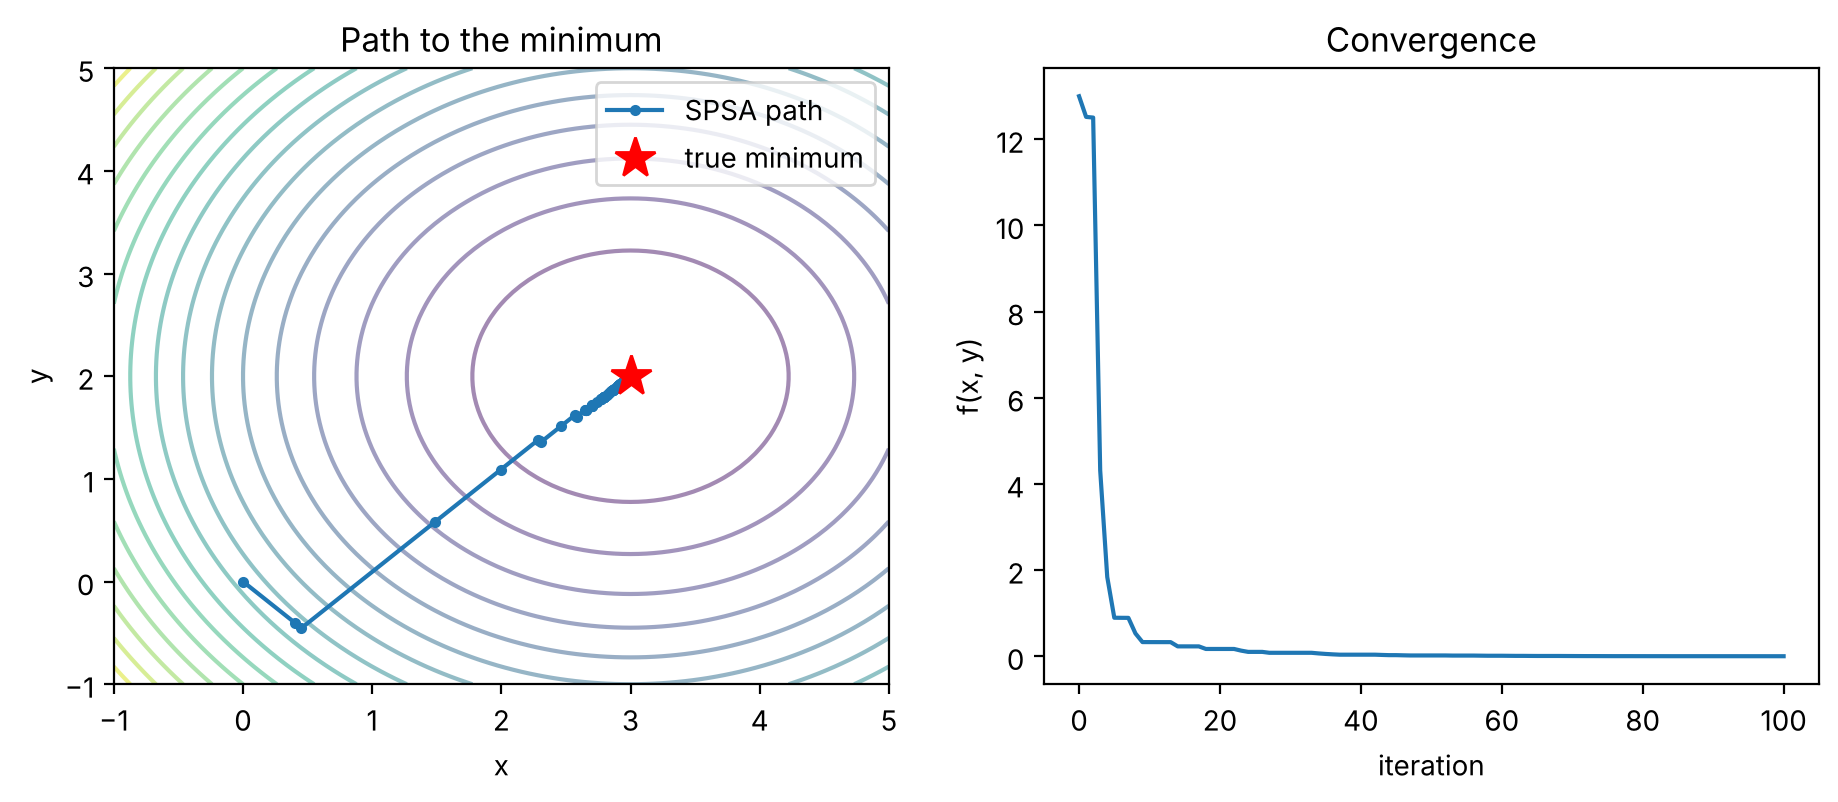

In [3]:
path = np.array(path)
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
gx, gy = np.meshgrid(np.linspace(-1, 5, 100), np.linspace(-1, 5, 100))
plt.contour(gx, gy, f([gx, gy]), levels=20, alpha=0.5)
plt.plot(path[:, 0], path[:, 1], "o-", markersize=3, label="SPSA path")
plt.plot(3, 2, "r*", markersize=15, label="true minimum")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Path to the minimum"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(values)
plt.xlabel("iteration"); plt.ylabel("f(x, y)"); plt.title("Convergence")
plt.show()

## Training a small neural network

**Task:** separate two half-moon shaped groups of points (2 classes).

**Network:** 2 inputs → 8 hidden neurons (tanh) → 1 output (sigmoid).

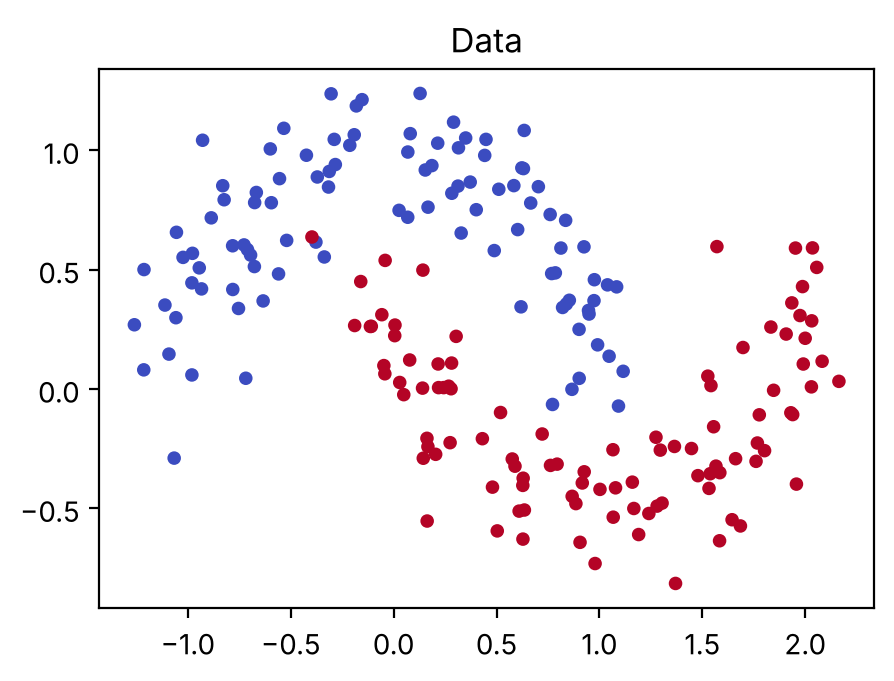

In [ ]:
X, y = make_moons(n_samples=200, noise=0.15, random_state=42)
y = y.reshape(-1, 1)

plt.figure(figsize=(5, 3.5))
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", s=15)
plt.title("Data"); plt.show()

In [5]:
def init_weights():
    rng = np.random.default_rng(0)
    layer1 = rng.normal(0, 0.5, size=(3, 8))     # 2 inputs + 1 bias  -> 8 neurons
    layer2 = rng.normal(0, 0.5, size=(9, 1))     # 8 neurons + 1 bias -> 1 output
    return [layer1, layer2]

def add_bias(A):
    return np.hstack([A, np.ones((len(A), 1))])

def predict(w, inputs):
    hidden = np.tanh(add_bias(inputs) @ w[0])
    return 1 / (1 + np.exp(-(add_bias(hidden) @ w[1])))

def loss_fn(w):                                   # binary cross-entropy
    p = np.clip(predict(w, X), 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def accuracy(w):
    return np.mean((predict(w, X) > 0.5) == y)

### Layer-wise SPSA (no backpropagation)

We update **one layer at a time** while the other layer stays fixed:

- change layer 1 using SPSA
- then change layer 2 using SPSA
- repeat

In [6]:
EPOCHS = 1000

w = init_weights()
spsa_losses = []

for epoch in range(EPOCHS):
    for layer in [0, 1]:                          # one layer at a time

        def layer_loss(new_weights):              # loss when only this layer changes
            trial = list(w)
            trial[layer] = new_weights
            return loss_fn(trial)

        a = 1.0 / (epoch + 1)**0.2
        c = 0.1 / (epoch + 1)**0.101
        w[layer] = spsa_step(layer_loss, w[layer], a, c)

    spsa_losses.append(loss_fn(w))

w_spsa = w
print("SPSA  final loss: %.3f   accuracy: %.1f%%" % (spsa_losses[-1], 100 * accuracy(w_spsa)))

SPSA  final loss: 0.046   accuracy: 99.5%


### SGD with backpropagation (for comparison)

Here the exact gradient is calculated with the chain rule. We use all 200 points in each step.

In [7]:
w = init_weights()                                # same starting weights
sgd_losses = []

for epoch in range(EPOCHS):
    # forward pass
    hidden = np.tanh(add_bias(X) @ w[0])
    output = 1 / (1 + np.exp(-(add_bias(hidden) @ w[1])))

    # backward pass
    error2 = (output - y) / len(X)
    grad2  = add_bias(hidden).T @ error2
    error1 = (error2 @ w[1][:-1].T) * (1 - hidden**2)
    grad1  = add_bias(X).T @ error1

    # update both layers
    w[0] = w[0] - 1.0 * grad1
    w[1] = w[1] - 1.0 * grad2
    sgd_losses.append(loss_fn(w))

w_sgd = w
print("SGD   final loss: %.3f   accuracy: %.1f%%" % (sgd_losses[-1], 100 * accuracy(w_sgd)))

SGD   final loss: 0.029   accuracy: 99.5%


### Adam with backpropagation (for comparison)

Adam uses the same exact gradient as SGD, but it changes how the step is taken:

- `m` = running average of the gradient (momentum, smooths the direction)
- `v` = running average of the squared gradient (gives each weight its own step size)
- Both start at 0, so they are bias-corrected: `m_hat = m / (1 - beta1^t)`, `v_hat = v / (1 - beta2^t)`
- Update: `w = w - lr * m_hat / (sqrt(v_hat) + eps)`

We use `lr = 0.01`. Adam's usual default of 0.001 is too slow to converge in 1000 steps here.

In [ ]:
def backprop_gradients(w):                        # same chain rule as in the SGD cell
    hidden = np.tanh(add_bias(X) @ w[0])
    output = 1 / (1 + np.exp(-(add_bias(hidden) @ w[1])))
    error2 = (output - y) / len(X)
    grad2  = add_bias(hidden).T @ error2
    error1 = (error2 @ w[1][:-1].T) * (1 - hidden**2)
    grad1  = add_bias(X).T @ error1
    return [grad1, grad2]

lr, beta1, beta2, eps = 0.01, 0.9, 0.999, 1e-8

w = init_weights()                                # same starting weights
m = [np.zeros_like(layer) for layer in w]         # 1st moment (mean of gradients)
v = [np.zeros_like(layer) for layer in w]         # 2nd moment (mean of squared gradients)
adam_losses = []

for t in range(1, EPOCHS + 1):
    grads = backprop_gradients(w)
    for i in [0, 1]:
        m[i] = beta1 * m[i] + (1 - beta1) * grads[i]
        v[i] = beta2 * v[i] + (1 - beta2) * grads[i]**2
        m_hat = m[i] / (1 - beta1**t)             # bias correction
        v_hat = v[i] / (1 - beta2**t)
        w[i] = w[i] - lr * m_hat / (np.sqrt(v_hat) + eps)
    adam_losses.append(loss_fn(w))

w_adam = w
print("Adam  final loss: %.3f   accuracy: %.1f%%" % (adam_losses[-1], 100 * accuracy(w_adam)))

## Part 3: Compare the results

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(spsa_losses, label="Layer-wise SPSA")
plt.plot(sgd_losses, label="SGD (backpropagation)")
plt.plot(adam_losses, label="Adam (backpropagation)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Loss curve"); plt.legend()
plt.show()

In [ ]:
gx, gy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200))
grid = np.c_[gx.ravel(), gy.ravel()]

models = [("Layer-wise SPSA", w_spsa), ("SGD", w_sgd), ("Adam", w_adam)]
plt.figure(figsize=(15, 4))
for i, (name, w) in enumerate(models):
    zone = predict(w, grid).reshape(gx.shape)
    plt.subplot(1, 3, i + 1)
    plt.contourf(gx, gy, zone, levels=[0, 0.5, 1], cmap="coolwarm", alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", s=15)
    plt.title(name + " decision boundary")
plt.show()

## Conclusion

- SPSA found the minimum of the simple function using only function values.
- Layer-wise SPSA trained the network **without backpropagation**.
- SGD and Adam reached a lower loss, because they use the exact gradient. SPSA only estimates it.
- Adam adapts the step size for each weight, so it needs a much smaller learning rate (0.01) than SGD (1.0) and is less sensitive to how the gradients are scaled.
- SPSA is useful when the gradient is not available.
- Results depend on the starting weights and step size, so this one run is a demonstration, not proof that one method is always better.